In [1]:
#Which animal characteristics like the sex or animal species show up the most in animals 
#left behind by their owners?
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("shelter_animals.csv")
print(df.info())
print(df.head())
#Dropped the address for the surrenders since it is not needed.
df = df.drop(columns=["Found Address"])
print("Rows and Columns before cleaning", df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 18764 entries, 0 to 18763
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          18764 non-null  int64
 1   Source Date                 18764 non-null  str  
 2   Animal ID                   18764 non-null  int64
 3   Type                        18764 non-null  str  
 4   Source Name                 18764 non-null  str  
 5   Name                        11173 non-null  str  
 6   IsPreviouslySpayedNeutered  18764 non-null  bool 
 7   Sex                         18744 non-null  str  
 8   Primary Breed               18764 non-null  str  
 9   Primary Color               18764 non-null  str  
 10  Secondary Color             9913 non-null   str  
 11  Intake Health Condition     3054 non-null   str  
 12  Date of Birth               17200 non-null  str  
 13  Found Address               18663 non-null  str  
 14  Timestamp        

In [2]:
#Keeping the animal that were Surrendered or Abandoned to see what types of animals were left by their owners.
#Dropped any animals that had a duplicate Animal ID
#Changed the Source Date and Date of Birth into datetime.

In [3]:
keep = ["ACO - Owner Surrender", "Owner Surrender", "Abandoned"]
df = df[df["Source Name"].isin(keep)]
df["Source Date"] = pd.to_datetime(df["Source Date"], format="mixed")
df["Date of Birth"] = pd.to_datetime(df["Date of Birth"], format="mixed")

In [4]:
print("Rows and Columns after keeping animals that were given up", df.shape)
print(df.isnull().sum())
df.duplicated(subset='Animal ID').sum()

Rows and Columns after keeping animals that were given up (2018, 14)
ID                               0
Source Date                      0
Animal ID                        0
Type                             0
Source Name                      0
Name                           135
IsPreviouslySpayedNeutered       0
Sex                              0
Primary Breed                    0
Primary Color                    0
Secondary Color                870
Intake Health Condition       1761
Date of Birth                   65
Timestamp                        0
dtype: int64


np.int64(13)

In [5]:
#Will not drop all rows with missing values, as the missing information for a missing name,
#second color, and found address do not affect what the common characteristics found in animals that were surrendered
#by their owners.

In [6]:
df.duplicated(subset='Animal ID').sum()
df = df.drop_duplicates(subset=['Animal ID'])

In [7]:
print(df["Source Name"].value_counts())
print("Rows and Columns after cleaning", df.shape)
print(df.head())

Source Name
Owner Surrender          1724
ACO - Owner Surrender     186
Abandoned                  95
Name: count, dtype: int64
Rows and Columns after cleaning (2005, 14)
       ID         Source Date  Animal ID     Type            Source Name  \
2   39517 2026-10-21 16:08:00      36940      Cat        Owner Surrender   
3   39516 2026-10-21 16:08:00      36939      Cat        Owner Surrender   
14  39500 2026-10-21 13:32:00      36924  Reptile  ACO - Owner Surrender   
15  39499 2026-10-21 13:25:00      36923  Reptile  ACO - Owner Surrender   
20  39492 2026-10-21 12:05:00      36916      Dog        Owner Surrender   

         Name  IsPreviouslySpayedNeutered      Sex       Primary Breed  \
2       Aries                       False     Male  Domestic Shorthair   
3      Athena                        True   Female  Domestic Shorthair   
14  Toothless                       False   Female  American Alligator   
15      Hydro                       False  Unknown               Snake   
20

In [8]:
## Cleaning Log
#I kept only the animals that were surrendered by ACO-Owner Surrender, Owner Surrendered, or Abandoned.
#After droping the other rows I was left with 2018 rows out of the previous 18764. 
#I checked for duplicates and found 13, I took those out, leaving 2005 rows.
#I changed the Source Date and Date of Birth into datetime.

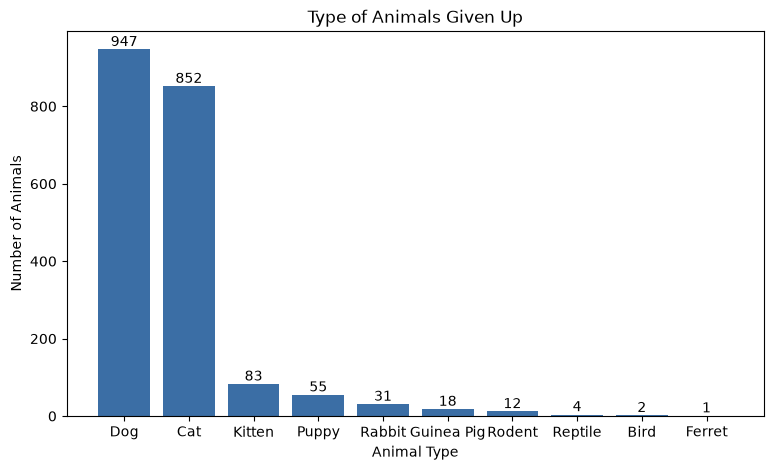

In [9]:
counts = df["Type"].value_counts()  
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(counts.index, counts.values, color="#3b6ea5")
ax.bar_label(bars)
ax.set_title("Type of Animals Given Up")
ax.set_xlabel("Animal Type")
ax.set_ylabel("Number of Animals")

plt.show()

In [10]:
#This bar shows that the animals that are given up the most are dogs and cats. Will count Kittens with Cat,
#as well as Puppy with dog. I will leave them into separate categories since it helps show that younger cats
#and dogs are not given up as much.


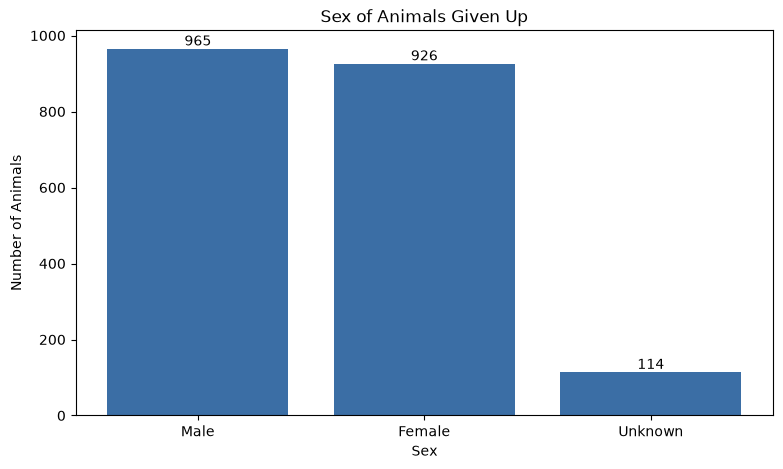

In [11]:
counts = df["Sex"].value_counts()
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(counts.index, counts.values, color="#3b6ea5")
ax.bar_label(bars)
ax.set_title("Sex of Animals Given Up")
ax.set_xlabel("Sex")
ax.set_ylabel("Number of Animals")

plt.show()

In [12]:
#This bar graph shows that the gender of the animal does not indicate whether one is given up more than the
#other, almost being a 50/50 split.

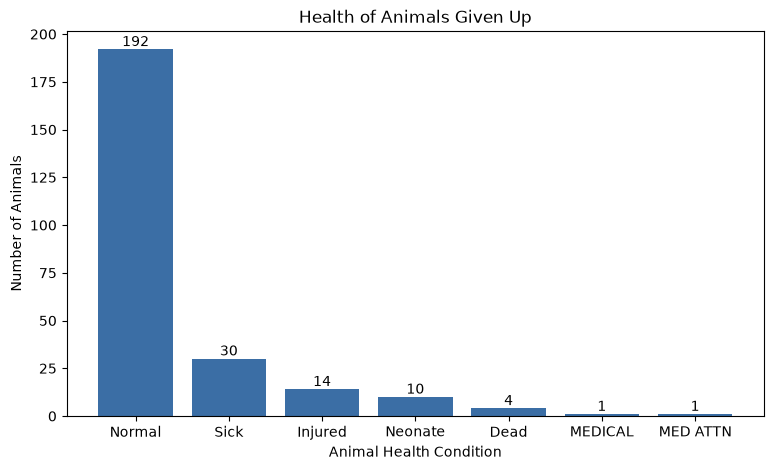

In [13]:
counts = df["Intake Health Condition"].value_counts()
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(counts.index, counts.values, color="#3b6ea5")
ax.bar_label(bars)
ax.set_title("Health of Animals Given Up")
ax.set_xlabel("Animal Health Condition")
ax.set_ylabel("Number of Animals")

plt.show()

In [14]:
#The bar graph does not show the total number of animals that were given up, the condition of the animals missing is unknown.
#I would infer that the missing number of animals had no recorded issue.
#This graph does show that animals that were given up that had health condition were low.

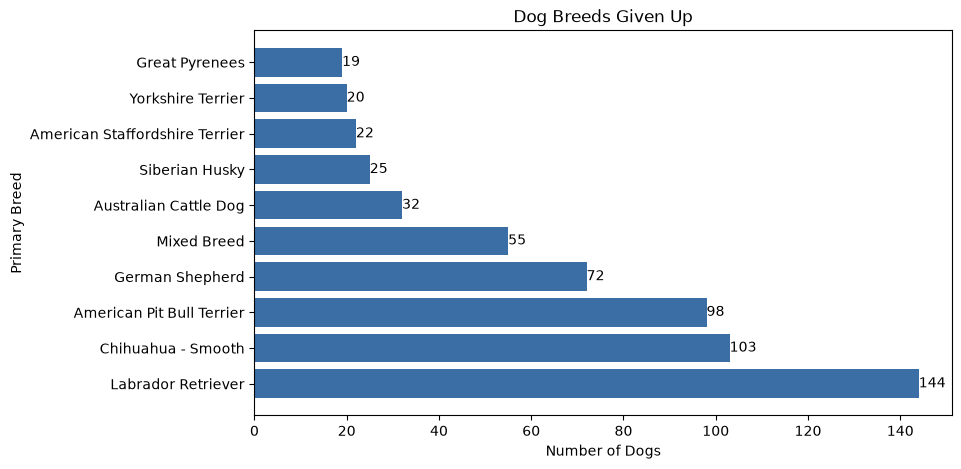

In [15]:
dogs = df[df["Type"].isin(["Dog", "Puppy"])]
counts = dogs["Primary Breed"].value_counts().head(10)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(counts.index, counts.values, color="#3b6ea5")
ax.bar_label(bars)
ax.set_title("Dog Breeds Given Up")
ax.set_xlabel("Number of Dogs")
ax.set_ylabel("Primary Breed")

plt.show()

In [16]:
#The bar graph shows that a majority of breeds given up are bigger dog breeds, with the chihuahua being a outlier

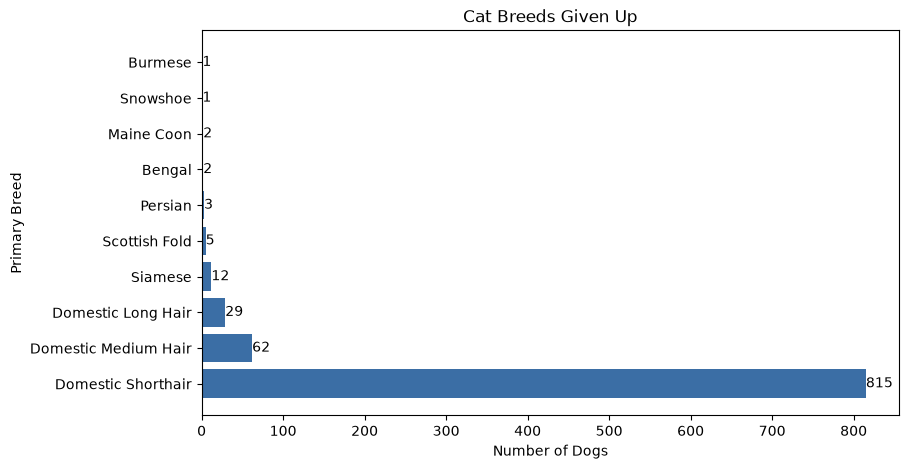

In [17]:
cats = df[df["Type"].isin(["Cat", "Kitten"])]
counts = cats["Primary Breed"].value_counts().head(10)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(counts.index, counts.values, color="#3b6ea5")
ax.bar_label(bars)
ax.set_title("Cat Breeds Given Up")
ax.set_xlabel("Number of Dogs")
ax.set_ylabel("Primary Breed")

plt.show()

In [18]:
#The graph shows that the breed given up the most is the most common housecat breed.

In [19]:
#Conclusion: I found that it is mostly dogs and cats that are being surrendered to shelters. Despite them being
#overall healthy. For dogs it is mostly larger breeds being given up. For cats the breed does not matter as much
#being that the most common breed is given up the most. 